# 02 · Exploratory data analysis of PTB-XL

Task T6 (chat DL 02). This notebook only **runs** `src/eda.py` and **shows** its results.
All the computation lives in the script, so the numbers in the reports come from one place:
`results/logs/eda.json`, turned into LaTeX macros by `report/make_numbers.py`.

Decisions behind this analysis: `docs/DECISIONS.md`, D12 (scope, outputs, codings) and O3
(records without a diagnostic superclass, closed in D12).

Run it from VS Code with the project's `.venv` kernel. It takes about a minute, mostly
to load the 1 GB signal cache.

In [1]:
import json
import sys
from pathlib import Path

# The notebook lives in notebooks/; the package src/ is one level up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from IPython.display import Image, display
from src import eda

def show(name: str) -> None:
    """Display report/figures/<name>.png."""
    display(Image(filename=str(eda.FIG_DIR / f"{name}.png")))

## 1. Run the whole analysis

`eda.main()` rewrites `eda.json` and every `eda_*` figure, and prints a summary.

In [2]:
eda.main()

with open(eda.LOG_PATH, encoding="utf-8") as f:
    result = json.load(f)
S, T = result["scalars"], result["tables"]
print(result["meta"])

Metadata and cache agree: 21799 records.
Loading the signals (about 1 GB)...

== Overview ==
  n_records_all: 21799
  n_patients_all: 18869
  n_labelled_all: 21388
  n_records_train: 17418
  n_patients_train: 15023
  n_labelled_train: 17084
  n_records_val: 2183
  n_patients_val: 1942
  n_labelled_val: 2146
  n_records_test: 2198
  n_patients_test: 1904
  n_labelled_test: 2158

== Records without superclass (O3) ==
  n_nosuper_all: 411
  n_nosuper_pacemaker_field: 277
  n_nosuper_with_rhythm_code: 409
  n_nosuper_with_form_code: 41
  n_nosuper_rhythm_only: 370
  n_nosuper_train: 334
  n_nosuper_val: 37
  n_nosuper_test: 40
  per fold: {'fold_1': 36, 'fold_2': 43, 'fold_3': 42, 'fold_4': 44, 'fold_5': 39, 'fold_6': 44, 'fold_7': 42, 'fold_8': 44, 'fold_9': 37, 'fold_10': 40}
  most frequent codes:
    PACE    284  rhythm             normal functioning artificial pacemaker
    AFIB     63  rhythm             atrial fibrillation
    AFLT     49  rhythm             atrial flutter
    ABQRS

## 2. Splits and records without a superclass (O3)

The official stratified folds are used: train = folds 1-8, validation = fold 9, test = fold 10.
Records whose SCP codes contain no diagnostic statement have no superclass. They carry mostly
rhythm statements, which PTB-XL does not map to a diagnostic superclass, so a target of five
zeros would be a false "no pathology" label. They are left out of the three splits (D12).

In [3]:
for split in ["train", "val", "test"]:
    print(f"{split:5s}  records {S[f'n_records_{split}']:6d}   "
          f"labelled {S[f'n_labelled_{split}']:6d}   "
          f"without superclass {S[f'n_nosuper_{split}']:4d}")
print("without superclass per fold:", T["nosuper_per_fold"])
print("most frequent codes:", [(r["code"], r["count"], r["kind"]) for r in T["nosuper_codes"][:6]])

train  records  17418   labelled  17084   without superclass  334
val    records   2183   labelled   2146   without superclass   37
test   records   2198   labelled   2158   without superclass   40
without superclass per fold: {'fold_1': 36, 'fold_2': 43, 'fold_3': 42, 'fold_4': 44, 'fold_5': 39, 'fold_6': 44, 'fold_7': 42, 'fold_8': 44, 'fold_9': 37, 'fold_10': 40}
most frequent codes: [('PACE', 284, 'rhythm'), ('AFIB', 63, 'rhythm'), ('AFLT', 49, 'rhythm'), ('ABQRS', 17, 'form'), ('PSVT', 15, 'rhythm'), ('PVC', 15, 'form')]


## 3. Classes

(a) Labelled records per superclass. (b) Share of the records of each split that carry each
class: if the folds are well stratified, the three bars of a class have about the same height.
The classes overlap (a record can have several), so the shares of a split add up to more than 100 %.

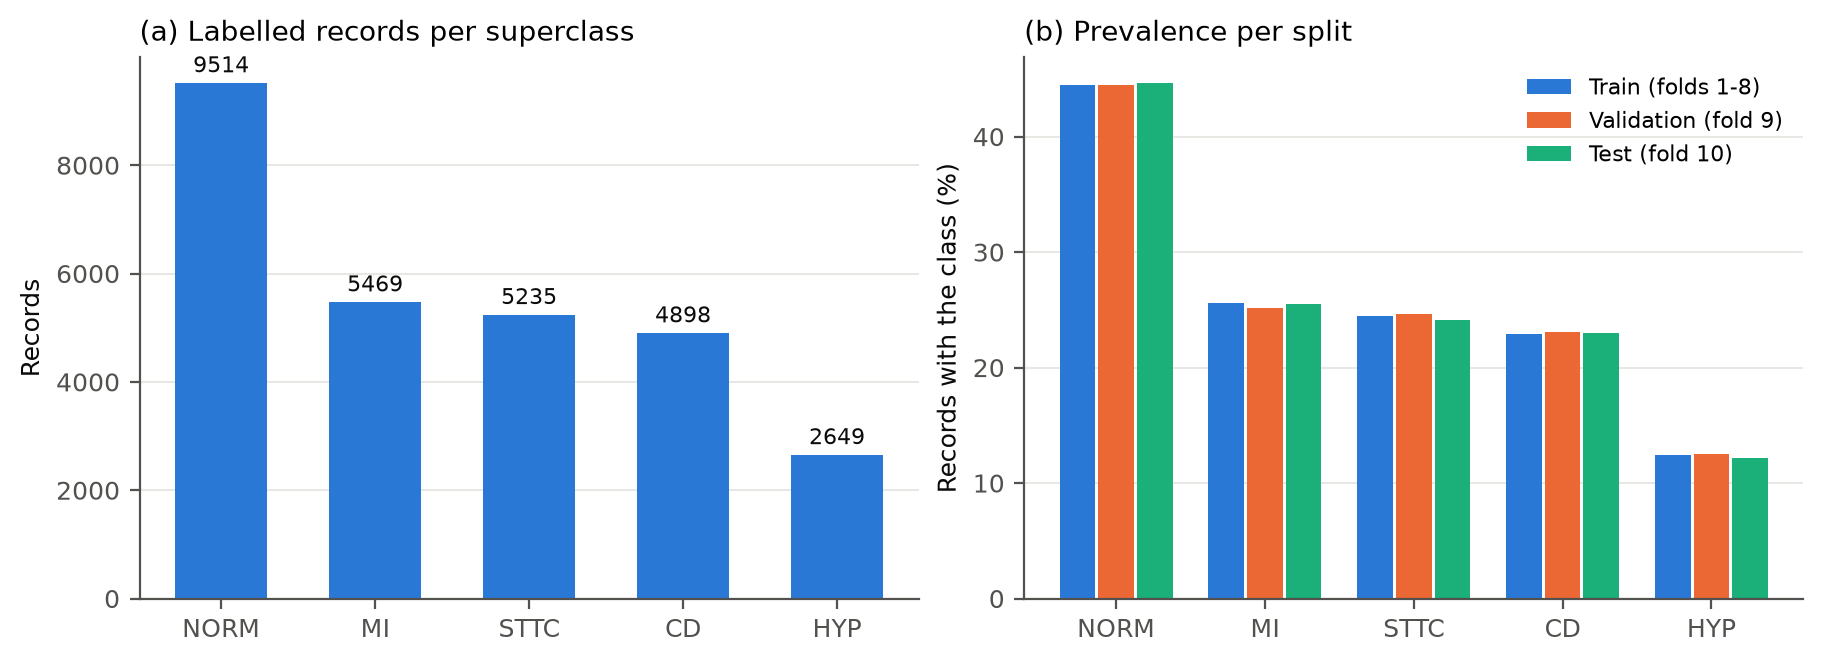

imbalance ratio (train, largest / smallest class): 3.58
records with more than one superclass: 24.1 %


In [4]:
show("eda_class_counts")
print("imbalance ratio (train, largest / smallest class):", round(S["imbalance_ratio_train"], 2))
print("records with more than one superclass:", f"{100 * S['frac_multilabel_all']:.1f} %")

(a) Co-occurrence, read by rows: of the records with the row class, the percentage that also
carries the column class. It is computed as $C = Y^\top Y$ (records with both classes), each
row divided by its diagonal entry. The matrix is not symmetric. (b) The most frequent label
combinations, in orange those with several superclasses.

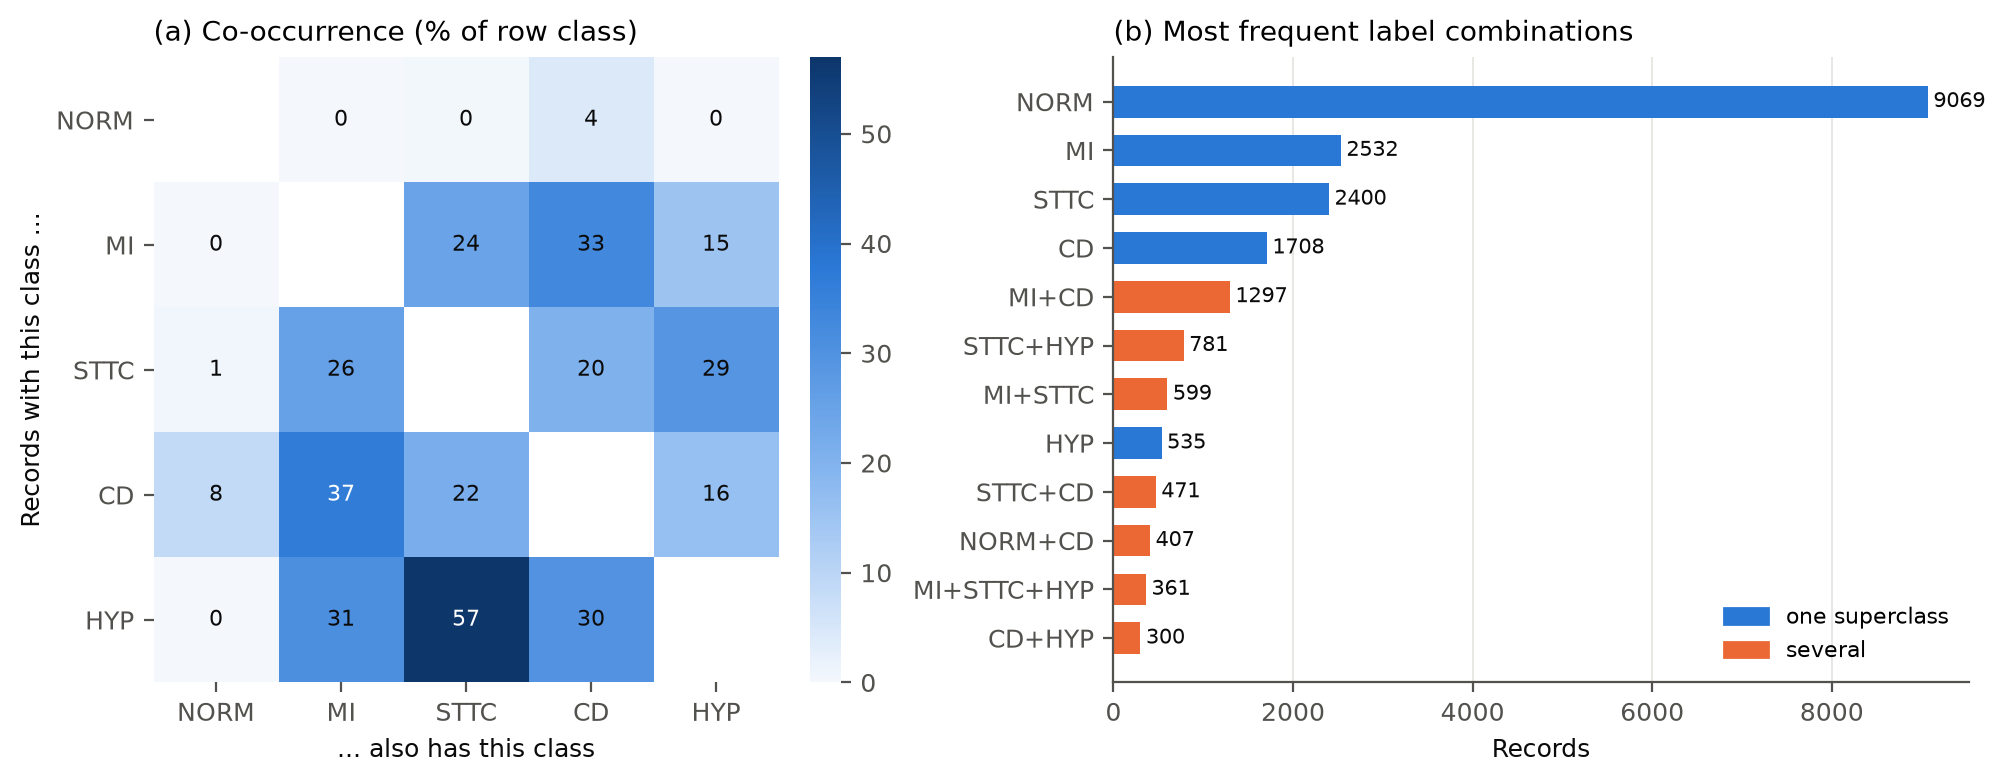

NORM together with another class: 445 records; codes: [('IRBBB', 250, 'CD'), ('IVCD', 106, 'CD'), ('1AVB', 38, 'CD'), ('NST_', 31, 'STTC'), ('LAFB', 21, 'CD')]


In [5]:
show("eda_label_cooccurrence")
print("NORM together with another class:", S["n_norm_with_other"], "records; codes:",
      [(r["code"], r["count"], r["class"]) for r in T["norm_with_other_codes"][:5]])

Prevalence of each class in each of the ten folds. Flat lines mean the stratification keeps the
class balance in every fold, including validation and test.

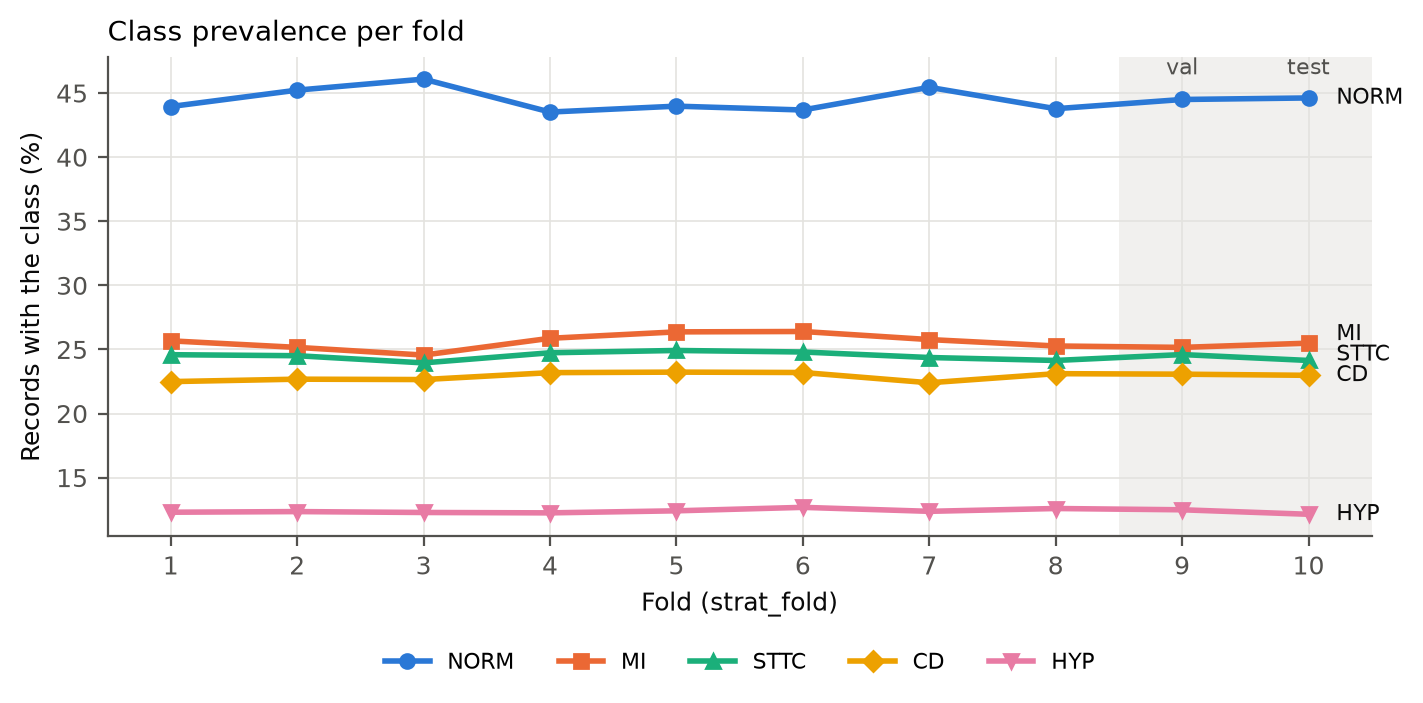

largest gap between a fold and the whole dataset: 1.61 percentage points


In [6]:
show("eda_fold_distribution")
print("largest gap between a fold and the whole dataset:",
      f"{S['max_fold_prev_gap_pp']:.2f} percentage points")

## 4. Demographics

Ages above 89 are stored as 300 for privacy (`ptbxl_v102_changelog.txt`, line 2): they are counted
apart and left out of the histogram and the medians. The meaning of `sex` 0/1 is not given in the
dataset files, so it is shown as "sex 0 / sex 1" until it is checked in the dataset paper [verify].

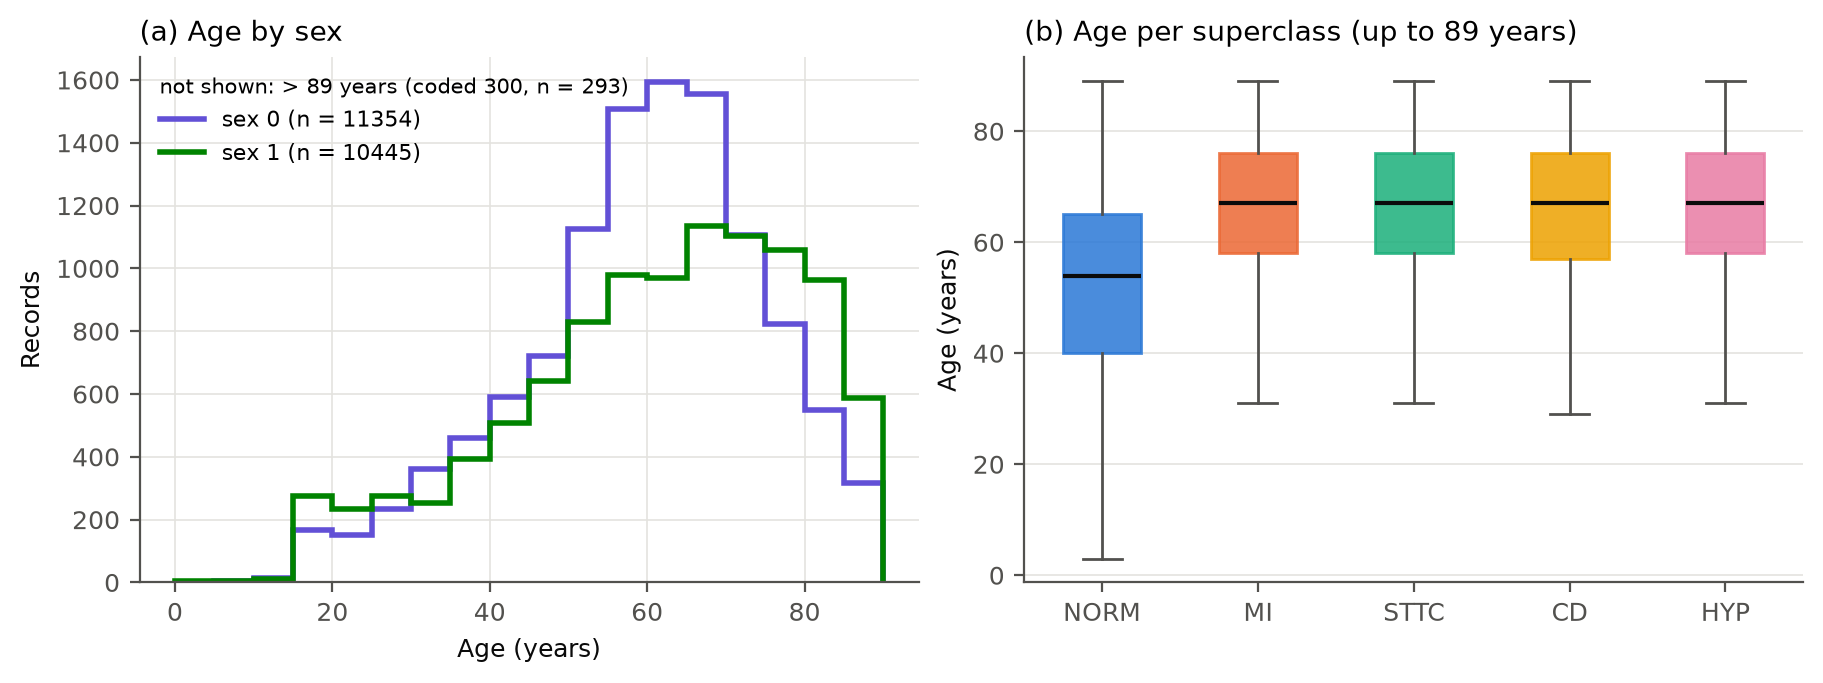

median age per class: {'NORM': 54.0, 'MI': 67.0, 'STTC': 67.0, 'CD': 67.0, 'HYP': 67.0}
patients with several records: 2111 | most records for one patient: 10


In [7]:
show("eda_age_sex")
print("median age per class:", {c: S[f"age_median_{c}"] for c in ["NORM", "MI", "STTC", "CD", "HYP"]})
print("patients with several records:", S["n_patients_several_records"],
      "| most records for one patient:", S["max_records_per_patient"])

## 5. Data quality

(a) Records whose free-text quality columns contain a note, per split. (b) The same, as the
share of the records of each class. Nothing is excluded (D12): the test set keeps real-world noise.
The reports were validated by a person for all validation and test records, but not for all
training records.

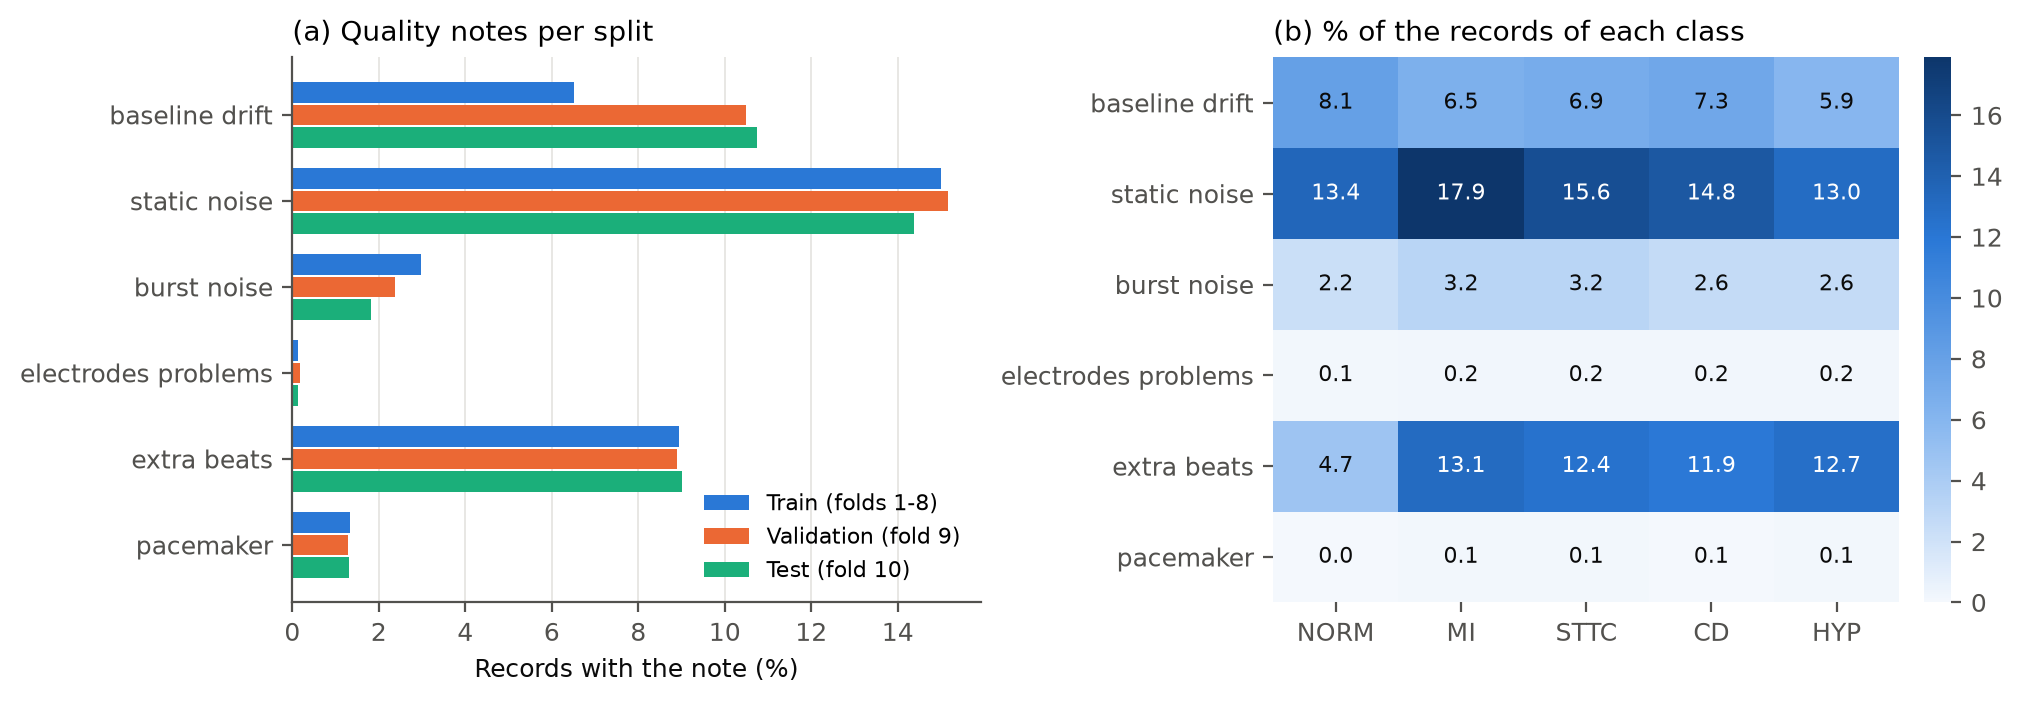

train  validated by human: 67.0 %   any quality note: 30.0 %
val    validated by human: 100.0 %   any quality note: 32.0 %
test   validated by human: 100.0 %   any quality note: 30.9 %


In [8]:
show("eda_signal_quality")
for split in ["train", "val", "test"]:
    print(f"{split:5s}  validated by human: {100 * S[f'frac_validated_by_human_{split}']:.1f} %   "
          f"any quality note: {100 * S[f'frac_any_quality_flag_{split}']:.1f} %")

## 6. Signals (training records only)

(a) Standard deviation of all samples of each lead: these are the statistics used to normalise
the inputs (D3), computed with the same functions as the DataLoader. (b) Peak-to-peak amplitude
of each record, per lead. The precordial leads (V1-V6) have a wider range than the limb leads,
which is why each lead is standardised separately.

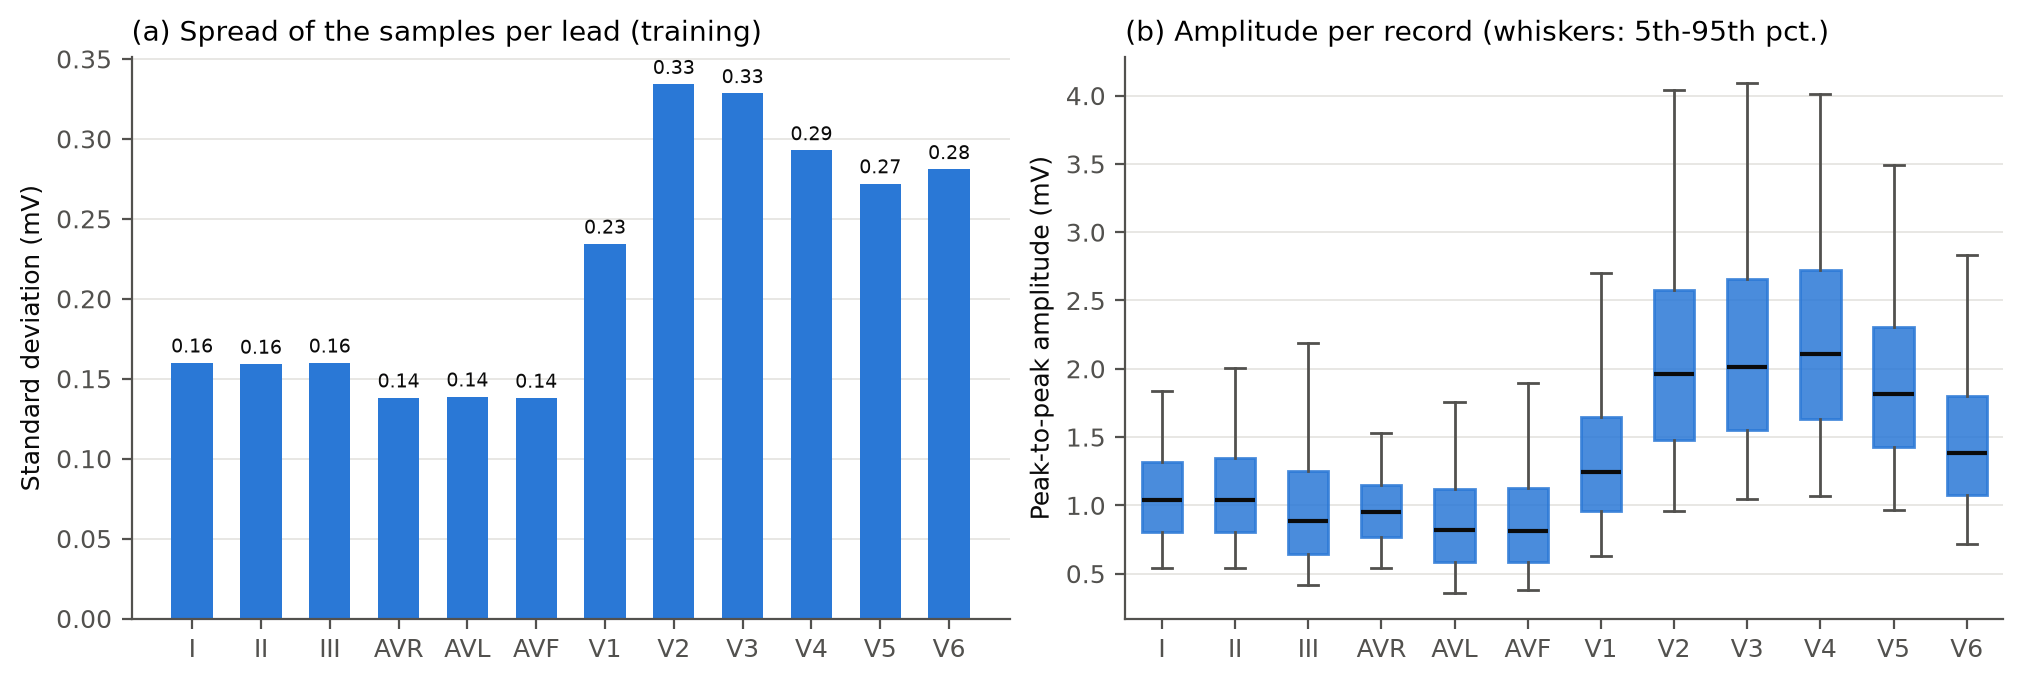

std ratio, widest / narrowest lead: 2.42
NaN values: 0 | flat leads: [{'ecg_id': 12722, 'lead': 'V5'}]


In [9]:
show("eda_lead_stats")
print("std ratio, widest / narrowest lead:", round(S["lead_std_ratio_max_min"], 2))
print("NaN values:", S["n_nan_values_train"], "| flat leads:", T["flat_leads_train"])

Lead II of one training record per superclass, each record carrying that class only, drawn at
random with seed 42 (not hand-picked). Raw values in mV, before normalisation.

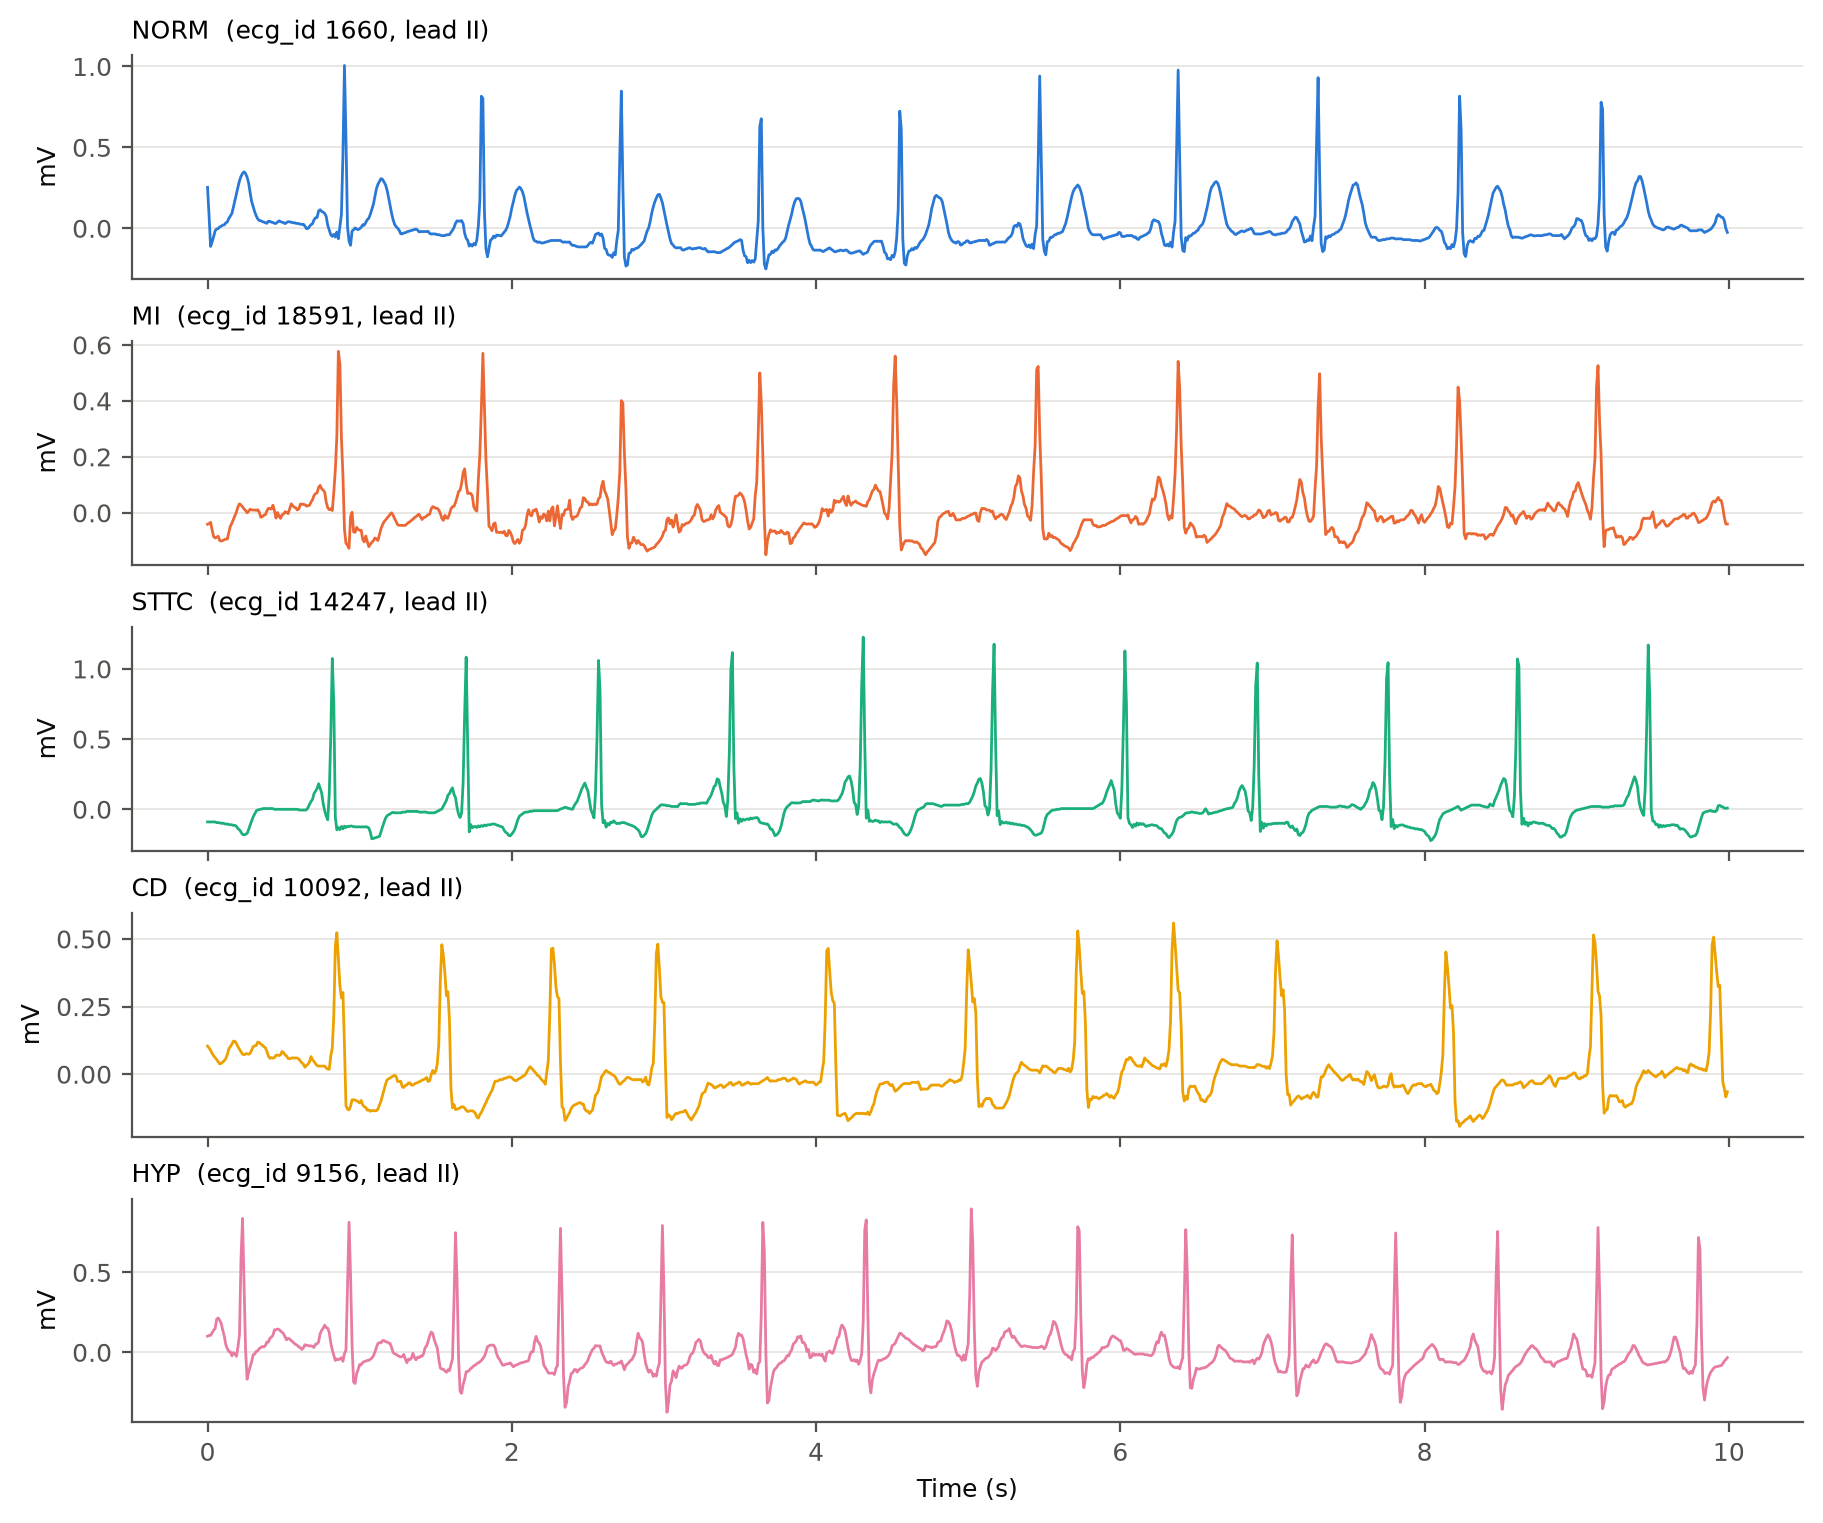

In [10]:
show("eda_example_traces")

What one input to the models looks like: the 12 leads of the NORM example, a tensor of shape
(12, 1000) = 12 leads x 10 s at 100 Hz.

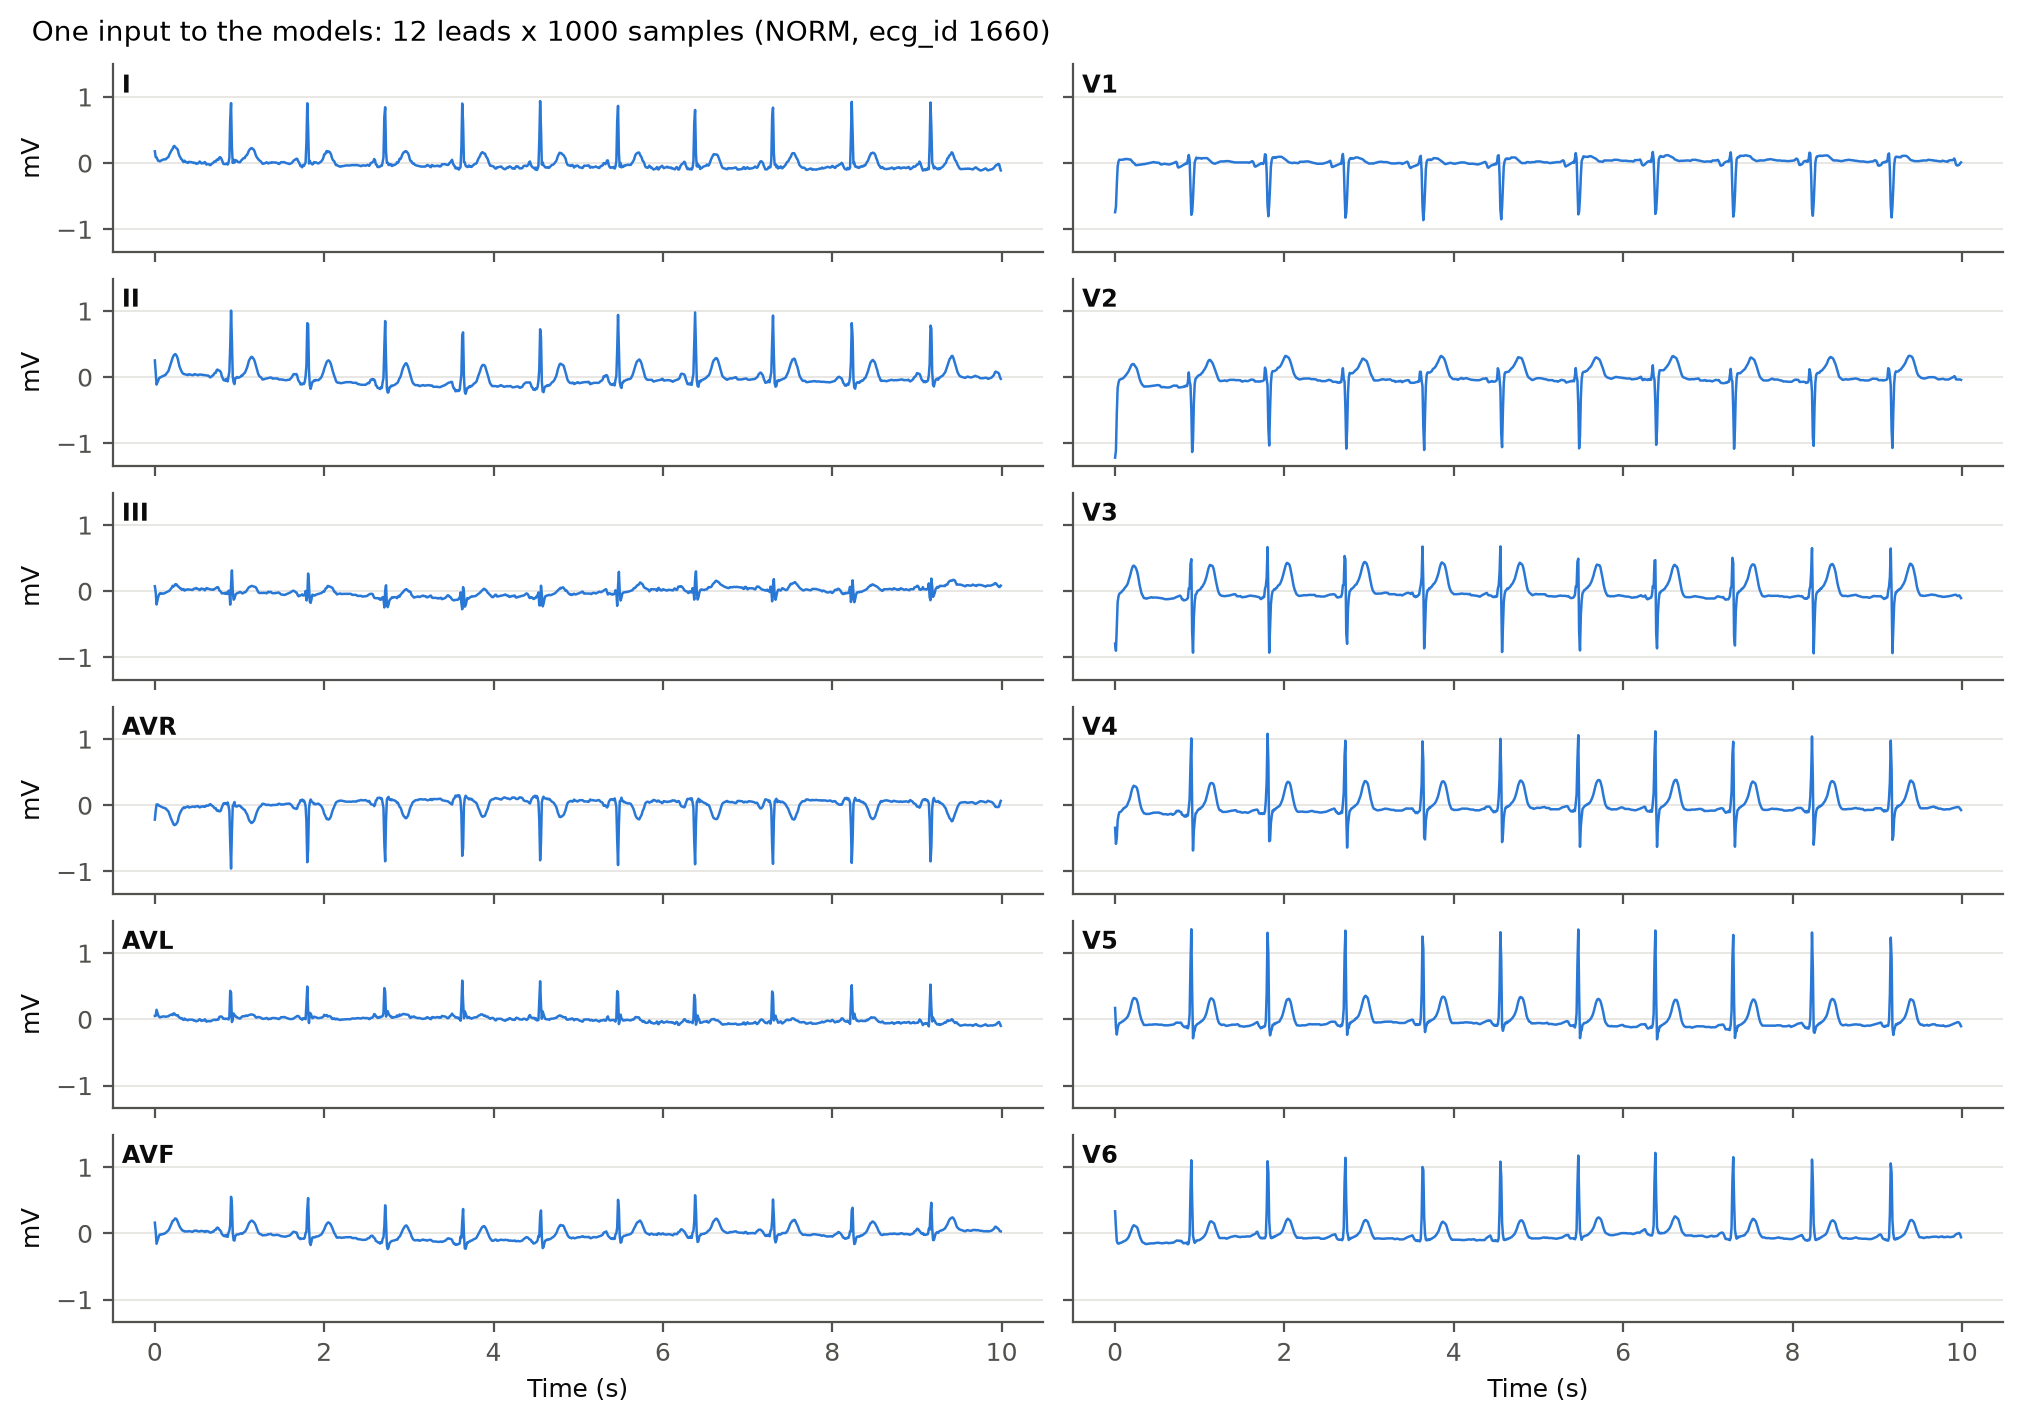

In [11]:
show("eda_example_12lead")